<a href="https://colab.research.google.com/github/EniodeSousa/FNO_Experiments/blob/main/fno_navier_stokes_2d.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fourier Neural Operator for 2-d Navier–Stokes (vorticity form)

Reproduces Section 5.3 of Li et al., *Fourier Neural Operator for Parametric PDEs* (ICLR 2021),
first column of Table 1:

$$\partial_t w + u\cdot\nabla w = \nu\Delta w + f,\qquad \nabla\cdot u = 0,\qquad w = \nabla\times u,\qquad x\in\mathbb T^2=[0,1)^2,$$

with $\nu = 10^{-3}$ and $f(x) = 0.1\big(\sin 2\pi(x_1+x_2) + \cos 2\pi(x_1+x_2)\big)$, and learns

$$G^\dagger:\ w|_{[0,10]} \longmapsto w|_{(10,50]}\qquad\text{(10 input frames} \to \text{40 output frames, on a } 64\times64 \text{ grid).}$$

**Pipeline**
1. Sample $w_0$ from a Gaussian random field (Appendix A.3.3).
2. Solve with a pseudo-spectral method in the vorticity–stream-function formulation, viscous term exact,
   nonlinear term with RK4 and 2/3 dealiasing; save $w$ at $t = 1, 2, \dots, 50$.
3. Train **FNO-3D** (Fourier in space-time, one pass) and, optionally, **FNO-2D** (Fourier in space,
   recurrent in time). Both use the configurations that reproduce Table 1's parameter counts.
4. Plots: data, learning curves, predicted trajectories, error growth in time, energy spectra,
   zero-shot evaluation on a finer grid, and inference time of the two models.

**Departures from the paper, to fit a Colab session** (all are parameters below):
* The paper solves on $256\times256$ with time step $10^{-4}$. We solve on $128\times128$ with an adaptive,
  CFL-limited time step; the notebook checks that this changes the data negligibly.
* The paper trains 500 epochs. Default here: 100 epochs for FNO-3D, with the learning-rate schedule
  compressed accordingly. Expect an error somewhat above the paper's 0.0086.

**Runtime** (select **Runtime → Change runtime type → T4 GPU**). Rough estimates: data generation 5–15 min;
FNO-3D training 1.5–2.5 h for 100 epochs (the paper reports 39 s per epoch on a V100; a T4 is slower).
The notebook prints the remaining time after every epoch; lower `EPOCHS3` if needed (even 15 epochs on
300 samples reached about 2.4% error in a small test). FNO-2D is optional and slower per epoch.
Colab free sessions can disconnect after a few hours; data and trained models are saved to disk as they finish,
but disk contents are lost when the runtime is recycled, so download them if you want to keep them.
Set `FAST = True` for a quick test run.

## 0. Setup and parameters

In [1]:
import math, time, os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU only (this will be slow)")
torch.manual_seed(0); np.random.seed(0)

FAST = False              # True: small, quick run to check that everything works

# --- PDE and data (paper, Section 5.3 and Appendix A.3.3) ---
NU       = 1e-3           # viscosity (paper: 1e-3 with T=50; 1e-4 with T=30; 1e-5 with T=20)
T_IN     = 10             # input: w at t = 1..T_IN
T_FINAL  = 50             # output: w at t = T_IN+1..T_FINAL
N_SOLVE  = 128            # solver grid (paper: 256); must be a multiple of S
S        = 64             # training / output grid (paper: 64)
N_TRAIN  = 1000           # paper: 1000 (10000 for the nu = 1e-4 large-data column)
N_TEST   = 200            # paper: 200
PRIOR    = "authors_code" # covariance of w0: "authors_code" = 2*7^3 (-Lap+49)^(-5/2) (as I recall the released
                          # generator), or "paper" = 7^(3/2) (-Lap+49)^(-5/2) (as printed). Same shape, different amplitude.

# --- FNO-3D (configuration that reproduces Table 1: 6,558,537 parameters) ---
MODES3, WIDTH3, PAD_T = 8, 20, 6
EPOCHS3, BATCH3 = 100, 10

# --- FNO-2D, recurrent (reproduces Table 1: 414,517 parameters). Slower to train: off by default ---
RUN_FNO2D = False
MODES2, WIDTH2 = 8, 20
EPOCHS2, BATCH2 = 30, 20

# --- optimisation (paper: Adam, lr 1e-3, halved every 100 of 500 epochs; here: halved 4 times in total) ---
LR, GAMMA, WEIGHT_DEC = 1e-3, 0.5, 1e-4

if FAST:
    N_SOLVE, S, T_FINAL, N_TRAIN, N_TEST = 64, 32, 20, 60, 12
    EPOCHS3, EPOCHS2, RUN_FNO2D = 3, 2, True

T_OUT = T_FINAL - T_IN
assert N_SOLVE % S == 0

device: cuda | Tesla T4


## 1. Initial vorticity: a Gaussian random field on the torus
Covariance $C = c\,(-\Delta + 49 I)^{-5/2}$, diagonal in $e_k = e^{2\pi i\langle k,x\rangle}$ with eigenvalues
$\lambda_k = c\,(4\pi^2|k|^2+49)^{-5/2}$. We set the $k=0$ mode to zero, so $\int w_0 = 0$, as a vorticity
on the torus must be (it is the curl of a periodic velocity). Samples lie in $H^s$ for every $s<3/2$.

In [2]:
def sample_w0(n_samples, n, device=device, dtype=torch.float32):
    c = 2 * 7.0**3 if PRIOR == "authors_code" else 7.0**1.5
    k1 = torch.fft.fftfreq(n, d=1.0 / n).to(device)
    k2 = torch.fft.rfftfreq(n, d=1.0 / n).to(device)
    K2 = k1[:, None]**2 + k2[None, :]**2
    sqrt_lam = torch.sqrt(c * (4 * math.pi**2 * K2 + 49.0) ** (-2.5))
    sqrt_lam[0, 0] = 0.0
    xi = torch.complex(torch.randn(n_samples, n, n // 2 + 1, device=device),
                       torch.randn(n_samples, n, n // 2 + 1, device=device)) / math.sqrt(2)
    return torch.fft.irfft2(sqrt_lam * xi, s=(n, n), norm="forward").to(dtype)

## 2. Reference solver: pseudo-spectral, integrating-factor RK4
Stream function: $-\Delta\psi = w$, velocity $u = (\partial_2\psi, -\partial_1\psi)$. In Fourier variables

$$\hat w_t = -\nu|2\pi k|^2\hat w + \underbrace{\big(-\widehat{u\cdot\nabla w} + \hat f\big)}_{\hat N(\hat w)}.$$

The viscous term is integrated exactly with the integrating factor $e^{-\nu|2\pi k|^2 t}$; $\hat N$ with RK4,
derivatives spectrally, products in physical space with the 2/3 rule. The time step is chosen in every unit
time interval from the current velocity, $\Delta t = \text{CFL}/(n\max(|u_1|+|u_2|))$, safely below the RK4
stability limit. (The paper uses Crank–Nicolson for the viscous term with an explicit nonlinear term.)

In [3]:
def forcing(n, device=device, dtype=torch.float32):
    x = torch.arange(n, device=device, dtype=dtype) / n
    X1, X2 = torch.meshgrid(x, x, indexing="ij")
    return 0.1 * (torch.sin(2 * math.pi * (X1 + X2)) + torch.cos(2 * math.pi * (X1 + X2)))

@torch.no_grad()
def ns_solve(w0, T, nu=NU, f=None, cfl=0.7, dt_max=0.02, record_times=None):
    """w0: (B, n, n). Integrates to time T; returns w at the integer times in record_times, shape (B, len, n, n)."""
    B, n, _ = w0.shape
    dev, dt_type = w0.device, w0.dtype
    k1 = 2 * math.pi * torch.fft.fftfreq(n, d=1.0 / n).to(dev)[:, None]
    k2 = 2 * math.pi * torch.fft.rfftfreq(n, d=1.0 / n).to(dev)[None, :]
    K2 = k1**2 + k2**2
    K2inv = torch.where(K2 > 0, 1.0 / K2, torch.zeros_like(K2))
    i1 = torch.fft.fftfreq(n, d=1.0 / n).to(dev).abs()[:, None]
    i2 = torch.fft.rfftfreq(n, d=1.0 / n).to(dev)[None, :]
    dealias = ((i1 <= n / 3) & (i2 <= n / 3)).to(dt_type)
    f = forcing(n, dev, dt_type) if f is None else f
    fh = torch.fft.rfft2(f)

    def velocity(wh):
        ph = wh * K2inv
        return torch.fft.irfft2(1j * k2 * ph, s=(n, n)), torch.fft.irfft2(-1j * k1 * ph, s=(n, n))

    def N(wh):
        wh = wh * dealias
        u1, u2 = velocity(wh)
        w1 = torch.fft.irfft2(1j * k1 * wh, s=(n, n)); w2 = torch.fft.irfft2(1j * k2 * wh, s=(n, n))
        return -torch.fft.rfft2(u1 * w1 + u2 * w2) * dealias + fh

    record_times = list(range(1, int(T) + 1)) if record_times is None else record_times
    out, wh, t = [], torch.fft.rfft2(w0), 0.0
    if 0 in record_times: out.append(w0.clone())
    total_steps = 0
    for t_next in range(1, int(T) + 1):
        u1, u2 = velocity(wh)
        speed = (u1.abs() + u2.abs()).max().item()
        dt = min(dt_max, cfl / (n * speed + 1e-12))
        n_sub = int(math.ceil(1.0 / dt)); dt = 1.0 / n_sub
        E = torch.exp(-nu * K2 * dt / 2); E2 = E * E
        for _ in range(n_sub):
            a1 = N(wh)
            a2 = N(E * (wh + 0.5 * dt * a1))
            a3 = N(E * wh + 0.5 * dt * a2)
            a4 = N(E2 * wh + dt * E * a3)
            wh = E2 * wh + dt / 6 * (E2 * a1 + 2 * E * (a2 + a3) + a4)
        total_steps += n_sub
        if t_next in record_times: out.append(torch.fft.irfft2(wh, s=(n, n)))
    return torch.stack(out, dim=1), total_steps

**Sanity checks of the solver.**
1. *Exact solution.* Any $w$ depending only on $x_1+x_2$ has $u\cdot\nabla w = 0$ (the flow is a shear along the
   level lines of $w$). With $w_0 = 0$ the equation becomes linear and $w(t) = \frac{f}{8\pi^2\nu}\big(1-e^{-8\pi^2\nu t}\big)$.
   This checks the forcing, the viscous term and the time stepping.
2. *Self-convergence on a random initial condition:* halve the time step and double the grid,
   and compare at $t = 10$. Both differences should be small compared with the FNO's ~1% error.

In [4]:
n_chk = N_SOLVE
w_ex, _ = ns_solve(torch.zeros(1, n_chk, n_chk, device=device), T=5, dt_max=0.1, record_times=[5])
exact = forcing(n_chk) / (8 * math.pi**2 * NU) * (1 - math.exp(-8 * math.pi**2 * NU * 5))
print(f"exact solution test (t=5): relative error {(w_ex[0, 0] - exact).norm() / exact.norm():.2e}")

def fourier_upsample(w, m):
    """Exact trigonometric interpolation of (B, n, n) periodic data onto an m x m grid (m > n)."""
    n = w.shape[-1]
    wh = torch.fft.fft2(w, norm="forward")
    out = torch.zeros(w.shape[0], m, m, dtype=wh.dtype, device=w.device)
    h = n // 2
    for a in (slice(0, h), slice(-h, None)):
        for b in (slice(0, h), slice(-h, None)):
            out[:, a, b] = wh[:, a, b]
    return torch.fft.ifft2(out, norm="forward").real

w0c = sample_w0(2, N_SOLVE)
wA, stepsA = ns_solve(w0c, T=10, record_times=[10])
wB, _ = ns_solve(w0c, T=10, cfl=0.35, dt_max=0.01, record_times=[10])
wC, _ = ns_solve(fourier_upsample(w0c, 2 * N_SOLVE), T=10, record_times=[10])
rel = lambda p, q: ((p - q).norm() / q.norm()).item()
print(f"{stepsA} time steps to t=10 on {N_SOLVE}^2 grid")
print(f"time step halved:  relative difference {rel(wA, wB):.2e}")
print(f"grid doubled ({2*N_SOLVE}^2): relative difference {rel(wA, wC[:, :, ::2, ::2]):.2e}")

exact solution test (t=5): relative error 4.01e-07
500 time steps to t=10 on 128^2 grid
time step halved:  relative difference 3.33e-05
grid doubled (256^2): relative difference 2.26e-05


## 3. Generate the dataset
For each sample we save $w$ at $t=1,\dots,50$ on the $64\times64$ grid (subsampled from the solver grid).
For the test set we also keep the full solver resolution, for the zero-shot super-resolution experiment.
Data are saved to disk and reloaded automatically if you re-run the notebook.

In [5]:
def generate(n_samples, keep_full=False, batch=100):
    W, Wfull = [], []
    t_start = time.time(); st = N_SOLVE // S
    for i in range(0, n_samples, batch):
        b = min(batch, n_samples - i)
        traj, steps = ns_solve(sample_w0(b, N_SOLVE), T=T_FINAL)           # (b, T_FINAL, n, n)
        W.append(traj[:, :, ::st, ::st].cpu())
        if keep_full: Wfull.append(traj.cpu())
        el = time.time() - t_start
        print(f"  solved {i + b}/{n_samples}  ({steps} time steps, {el:.0f} s elapsed, ~{el/(i+b)*(n_samples-i-b):.0f} s left)")
    return torch.cat(W), (torch.cat(Wfull) if keep_full else None)

data_file = f"ns_data_nu{NU}_T{T_FINAL}_n{N_SOLVE}_N{N_TRAIN}.pt"
d = torch.load(data_file) if os.path.exists(data_file) else None
if d is not None:
    w_train, w_test, w_test_full = d["train"], d["test"], d["test_full"]
    print(f"loaded {data_file}")
else:
    t0 = time.time()
    w_train, _ = generate(N_TRAIN)
    w_test, w_test_full = generate(N_TEST, keep_full=True)
    print(f"data generation: {time.time() - t0:.0f} s")
    torch.save(dict(train=w_train, test=w_test, test_full=w_test_full), data_file)
# layout: (N, T_FINAL, S, S) with index j <-> time t = j + 1
print("train", tuple(w_train.shape), "| test", tuple(w_test.shape), "| test (full res)", tuple(w_test_full.shape))

  solved 100/1000  (3089 time steps, 28 s elapsed, ~249 s left)
  solved 200/1000  (3116 time steps, 56 s elapsed, ~222 s left)
  solved 300/1000  (3102 time steps, 83 s elapsed, ~195 s left)
  solved 400/1000  (3127 time steps, 111 s elapsed, ~167 s left)
  solved 500/1000  (3114 time steps, 139 s elapsed, ~139 s left)
  solved 600/1000  (3138 time steps, 167 s elapsed, ~112 s left)
  solved 700/1000  (3105 time steps, 195 s elapsed, ~84 s left)
  solved 800/1000  (3091 time steps, 223 s elapsed, ~56 s left)
  solved 900/1000  (3119 time steps, 251 s elapsed, ~28 s left)
  solved 1000/1000  (3115 time steps, 279 s elapsed, ~0 s left)
  solved 100/200  (3128 time steps, 28 s elapsed, ~28 s left)
  solved 200/200  (3106 time steps, 56 s elapsed, ~0 s left)
data generation: 336 s
train (1000, 50, 64, 64) | test (200, 50, 64, 64) | test (full res) (200, 50, 128, 128)


### Plot: one trajectory, and the energy spectrum of the data
The right panel is the radially averaged spectrum $E(|k|)=\sum_{\,||k|-\kappa|<1/2}|\hat w(k)|^2$ at a few times,
on the solver grid. It shows how much fine-scale content the operator must reproduce.

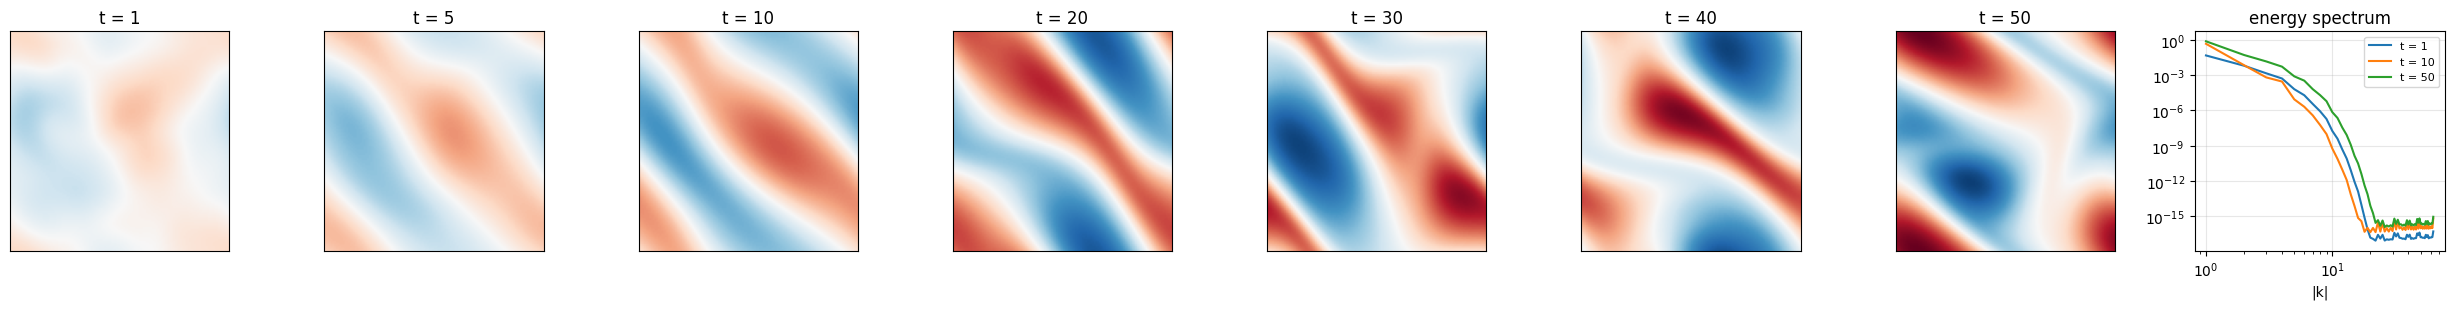

In [6]:
def radial_spectrum(w):
    """w: (..., n, n) real -> radially binned |w_hat|^2, averaged over leading dims."""
    n = w.shape[-1]
    wh = torch.fft.fft2(w, norm="forward").abs() ** 2
    k = torch.fft.fftfreq(n, d=1.0 / n)
    kr = torch.sqrt(k[:, None]**2 + k[None, :]**2).round().long()
    wh = wh.reshape(-1, n * n).mean(0)
    return torch.zeros(int(kr.max()) + 1).index_add_(0, kr.flatten(), wh)[: n // 2]

times = [1, 5, 10, 20, 30, 40, 50] if T_FINAL >= 50 else list(range(1, T_FINAL + 1, max(1, T_FINAL // 6)))
fig, axs = plt.subplots(1, len(times) + 1, figsize=(3.1 * (len(times) + 1), 3.2))
vm = w_test_full[0].abs().max().item()
for ax, t in zip(axs, times):
    ax.imshow(w_test_full[0, t - 1].T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-vm, vmax=vm)
    ax.set_title(f"t = {t}"); ax.set_xticks([]); ax.set_yticks([])
for t in [1, T_IN, T_FINAL]:
    axs[-1].loglog(np.arange(1, N_SOLVE // 2), radial_spectrum(w_test_full[:, t - 1])[1:], label=f"t = {t}")
axs[-1].set_xlabel("|k|"); axs[-1].set_title("energy spectrum"); axs[-1].legend(fontsize=8); axs[-1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 4. The two architectures
Both follow the paper's code: lifting $P$, 4 Fourier layers $v\mapsto \sigma\big(\mathrm{BN}(Wv + \mathcal F^{-1}(R\cdot\mathcal F v))\big)$
(ReLU and batch norm, no activation after the last layer), projection $Q$ through 128 hidden units.

* **FNO-3D**: input at each space-time point = the 10 input frames (repeated along time) + $(x_1,x_2,t)$,
  13 channels. Fourier transform in $(x_1,x_2,t)$, keeping $|k_1|,|k_2|<8$, $0\le k_3<8$ (4 corners of the
  real FFT). Time is not periodic, so the time axis is zero-padded by 6 before the FFT and cropped after.
  One forward pass outputs all 40 frames.
* **FNO-2D**: input = the last 10 frames + $(x_1,x_2)$, 12 channels; output = the next frame. Fourier in
  $(x_1,x_2)$ only (2 corners). Applied 40 times autoregressively, feeding its own predictions back.

In [7]:
class SpectralConv3d(nn.Module):
    def __init__(self, ci, co, m1, m2, m3):
        super().__init__()
        self.m = (m1, m2, m3); sc = 1 / (ci * co)
        self.w = nn.ParameterList([nn.Parameter(sc * torch.rand(ci, co, m1, m2, m3, dtype=torch.cfloat)) for _ in range(4)])
    def forward(self, v):
        B, C, n1, n2, n3 = v.shape; m1, m2, m3 = self.m
        vh = torch.fft.rfftn(v, dim=(-3, -2, -1))
        out = torch.zeros(B, self.w[0].shape[1], n1, n2, n3 // 2 + 1, dtype=torch.cfloat, device=v.device)
        mm = lambda x, w: torch.einsum("bixyz,ioxyz->boxyz", x, w)
        out[:, :, :m1, :m2, :m3]   = mm(vh[:, :, :m1, :m2, :m3],   self.w[0])
        out[:, :, -m1:, :m2, :m3]  = mm(vh[:, :, -m1:, :m2, :m3],  self.w[1])
        out[:, :, :m1, -m2:, :m3]  = mm(vh[:, :, :m1, -m2:, :m3],  self.w[2])
        out[:, :, -m1:, -m2:, :m3] = mm(vh[:, :, -m1:, -m2:, :m3], self.w[3])
        return torch.fft.irfftn(out, s=(n1, n2, n3), dim=(-3, -2, -1))


class SpectralConv2d(nn.Module):
    def __init__(self, ci, co, m1, m2):
        super().__init__()
        self.m = (m1, m2); sc = 1 / (ci * co)
        self.w = nn.ParameterList([nn.Parameter(sc * torch.rand(ci, co, m1, m2, dtype=torch.cfloat)) for _ in range(2)])
    def forward(self, v):
        B, C, n1, n2 = v.shape; m1, m2 = self.m
        vh = torch.fft.rfft2(v)
        out = torch.zeros(B, self.w[0].shape[1], n1, n2 // 2 + 1, dtype=torch.cfloat, device=v.device)
        out[:, :, :m1, :m2]  = torch.einsum("bixy,ioxy->boxy", vh[:, :, :m1, :m2],  self.w[0])
        out[:, :, -m1:, :m2] = torch.einsum("bixy,ioxy->boxy", vh[:, :, -m1:, :m2], self.w[1])
        return torch.fft.irfft2(out, s=(n1, n2))


def grid2d(B, n, device):
    x = torch.arange(n, device=device, dtype=torch.float32) / n              # periodic grid
    X1, X2 = torch.meshgrid(x, x, indexing="ij")
    return X1.expand(B, n, n), X2.expand(B, n, n)


class FNO3d(nn.Module):
    def __init__(self, modes=MODES3, width=WIDTH3, t_in=T_IN, t_out=T_OUT, pad_t=PAD_T):
        super().__init__()
        self.t_out, self.pad_t = t_out, pad_t
        self.P = nn.Linear(t_in + 3, width)
        self.K = nn.ModuleList([SpectralConv3d(width, width, modes, modes, modes) for _ in range(4)])
        self.W = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(4)])
        self.bn = nn.ModuleList([nn.BatchNorm3d(width) for _ in range(4)])
        self.Q = nn.Sequential(nn.Linear(width, 128), nn.ReLU(), nn.Linear(128, 1))
    def forward(self, w_in):                                  # (B, n, n, t_in) -> (B, n, n, t_out)
        B, n, _, ti = w_in.shape; T = self.t_out
        X1, X2 = grid2d(B, n, w_in.device)
        tt = torch.linspace(0, 1, T, device=w_in.device)
        h = torch.cat([w_in[:, :, :, None, :].expand(B, n, n, T, ti),
                       X1[..., None, None].expand(B, n, n, T, 1), X2[..., None, None].expand(B, n, n, T, 1),
                       tt[None, None, None, :, None].expand(B, n, n, T, 1)], dim=-1)
        h = self.P(h).permute(0, 4, 1, 2, 3)                  # (B, C, n, n, T)
        h = F.pad(h, (0, self.pad_t))
        for l in range(4):
            Bc, C, a, b, c = h.shape
            h = self.bn[l](self.K[l](h) + self.W[l](h.reshape(Bc, C, -1)).reshape(Bc, C, a, b, c))
            if l < 3: h = F.relu(h)
        h = h[..., :T]
        return self.Q(h.permute(0, 2, 3, 4, 1)).squeeze(-1)


class FNO2d(nn.Module):
    def __init__(self, modes=MODES2, width=WIDTH2, t_in=T_IN):
        super().__init__()
        self.P = nn.Linear(t_in + 2, width)
        self.K = nn.ModuleList([SpectralConv2d(width, width, modes, modes) for _ in range(4)])
        self.W = nn.ModuleList([nn.Conv1d(width, width, 1) for _ in range(4)])
        self.bn = nn.ModuleList([nn.BatchNorm2d(width) for _ in range(4)])
        self.Q = nn.Sequential(nn.Linear(width, 128), nn.ReLU(), nn.Linear(128, 1))
    def step(self, frames):                                   # (B, n, n, t_in) -> next frame (B, n, n)
        B, n, _, _ = frames.shape
        X1, X2 = grid2d(B, n, frames.device)
        h = self.P(torch.cat([frames, X1[..., None], X2[..., None]], dim=-1)).permute(0, 3, 1, 2)
        for l in range(4):
            Bc, C, a, b = h.shape
            h = self.bn[l](self.K[l](h) + self.W[l](h.reshape(Bc, C, -1)).reshape(Bc, C, a, b))
            if l < 3: h = F.relu(h)
        return self.Q(h.permute(0, 2, 3, 1)).squeeze(-1)
    def forward(self, w_in, t_out=T_OUT):                     # autoregressive rollout
        frames, preds = w_in, []
        for _ in range(t_out):
            nxt = self.step(frames)
            preds.append(nxt)
            frames = torch.cat([frames[..., 1:], nxt[..., None]], dim=-1)
        return torch.stack(preds, dim=-1)

count = lambda m: sum(p.numel() * (2 if p.is_complex() else 1) for p in m.parameters())
print(f"FNO-3D parameters: {count(FNO3d()):,}   (Table 1: 6,558,537)")
print(f"FNO-2D parameters: {count(FNO2d()):,}   (Table 1: 414,517)")

FNO-3D parameters: 6,558,537   (Table 1: 6,558,537)
FNO-2D parameters: 414,517   (Table 1: 414,517)


## 5. Training data in the model layout, normalisation, metric
Inputs `(N, S, S, 10)` = $w$ at $t=1..10$; targets `(N, S, S, 40)` = $w$ at $t=11..50$. We normalise by a single
mean and standard deviation (resolution independent). The metric is the paper's: relative $L^2$ error over the
whole space-time output of each sample.

In [8]:
to_io = lambda w: (w[:, :T_IN].permute(0, 2, 3, 1).contiguous(), w[:, T_IN:].permute(0, 2, 3, 1).contiguous())
Xtr, Ytr = to_io(w_train); Xte, Yte = to_io(w_test)
w_mean, w_std = w_train.mean().item(), w_train.std().item()
enc = lambda w: (w - w_mean) / w_std
dec = lambda v: v * w_std + w_mean
rel_l2 = lambda p, q: (p - q).flatten(1).norm(dim=1) / q.flatten(1).norm(dim=1)

@torch.no_grad()
def predict(model, X, batch):
    model.eval()
    return torch.cat([dec(model(enc(X[i:i + batch].to(device)))).cpu() for i in range(0, len(X), batch)])

def train(model, epochs, batch, name):
    model = model.to(device)
    opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DEC)
    sched = torch.optim.lr_scheduler.StepLR(opt, step_size=max(1, epochs // 5), gamma=GAMMA)
    Xg, Yg = enc(Xtr).to(device), Ytr.to(device)
    hist = {"train": [], "test": []}; t0 = time.time()
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(Xg), device=device); tot = 0.0
        for i in range(0, len(Xg), batch):
            idx = perm[i:i + batch]
            loss = rel_l2(dec(model(Xg[idx])), Yg[idx]).mean()
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(idx)
        sched.step()
        hist["train"].append(tot / len(Xg))
        hist["test"].append(rel_l2(predict(model, Xte, batch), Yte).mean().item())
        el = time.time() - t0
        print(f"[{name}] epoch {ep:3d} | train {hist['train'][-1]:.4f} | test {hist['test'][-1]:.4f} | "
              f"{el:.0f} s, ~{el/(ep+1)*(epochs-ep-1)/60:.0f} min left")
    torch.save(model.state_dict(), f"{name}.pt")
    return model, hist

## 6. Train FNO-3D

In [9]:
model3, hist3 = train(FNO3d(), EPOCHS3, BATCH3, "fno3d")
print(f"FNO-3D final test error: {hist3['test'][-1]:.4f}   (paper, 500 epochs: 0.0086)")

[fno3d] epoch   0 | train 0.2600 | test 0.1516 | 50 s, ~82 min left
[fno3d] epoch   1 | train 0.1228 | test 0.1129 | 96 s, ~79 min left
[fno3d] epoch   2 | train 0.0969 | test 0.1046 | 143 s, ~77 min left
[fno3d] epoch   3 | train 0.0861 | test 0.0887 | 190 s, ~76 min left
[fno3d] epoch   4 | train 0.0740 | test 0.0743 | 236 s, ~75 min left
[fno3d] epoch   5 | train 0.0661 | test 0.0717 | 283 s, ~74 min left
[fno3d] epoch   6 | train 0.0608 | test 0.0698 | 330 s, ~73 min left
[fno3d] epoch   7 | train 0.0587 | test 0.0613 | 376 s, ~72 min left
[fno3d] epoch   8 | train 0.0550 | test 0.0569 | 423 s, ~71 min left
[fno3d] epoch   9 | train 0.0517 | test 0.0516 | 470 s, ~70 min left
[fno3d] epoch  10 | train 0.0516 | test 0.0556 | 517 s, ~70 min left
[fno3d] epoch  11 | train 0.0508 | test 0.0570 | 563 s, ~69 min left
[fno3d] epoch  12 | train 0.0482 | test 0.0460 | 610 s, ~68 min left
[fno3d] epoch  13 | train 0.0463 | test 0.0498 | 657 s, ~67 min left
[fno3d] epoch  14 | train 0.0440 | t

## 7. (Optional) Train FNO-2D
The rollout is sequential (40 small passes per sample, and backpropagation through all of them), so each epoch
is several times slower than FNO-3D's, even though the model is 16× smaller. Set `RUN_FNO2D = True` above.

In [10]:
model2 = hist2 = None
if RUN_FNO2D:
    model2, hist2 = train(FNO2d(), EPOCHS2, BATCH2, "fno2d")
    print(f"FNO-2D final test error: {hist2['test'][-1]:.4f}   (paper, 500 epochs: 0.0128)")

## 8. Results
### 8a. Learning curves

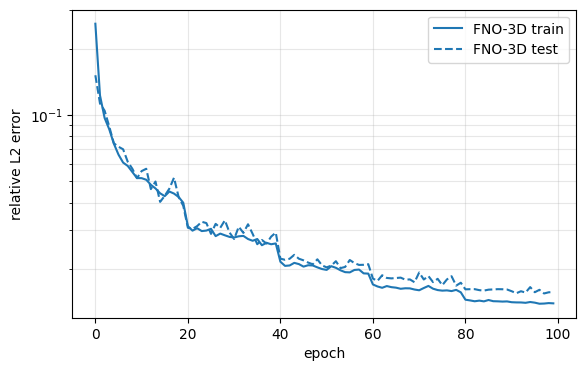

In [11]:
plt.figure(figsize=(6.5, 4))
plt.semilogy(hist3["train"], "C0", label="FNO-3D train"); plt.semilogy(hist3["test"], "C0--", label="FNO-3D test")
if hist2: plt.semilogy(hist2["train"], "C1", label="FNO-2D train"); plt.semilogy(hist2["test"], "C1--", label="FNO-2D test")
plt.xlabel("epoch"); plt.ylabel("relative L2 error"); plt.grid(alpha=.3, which="both"); plt.legend(); plt.show()

### 8b. A predicted trajectory (median test sample)
Rows: truth, FNO-3D, its error (and FNO-2D, if trained). Columns: output times.

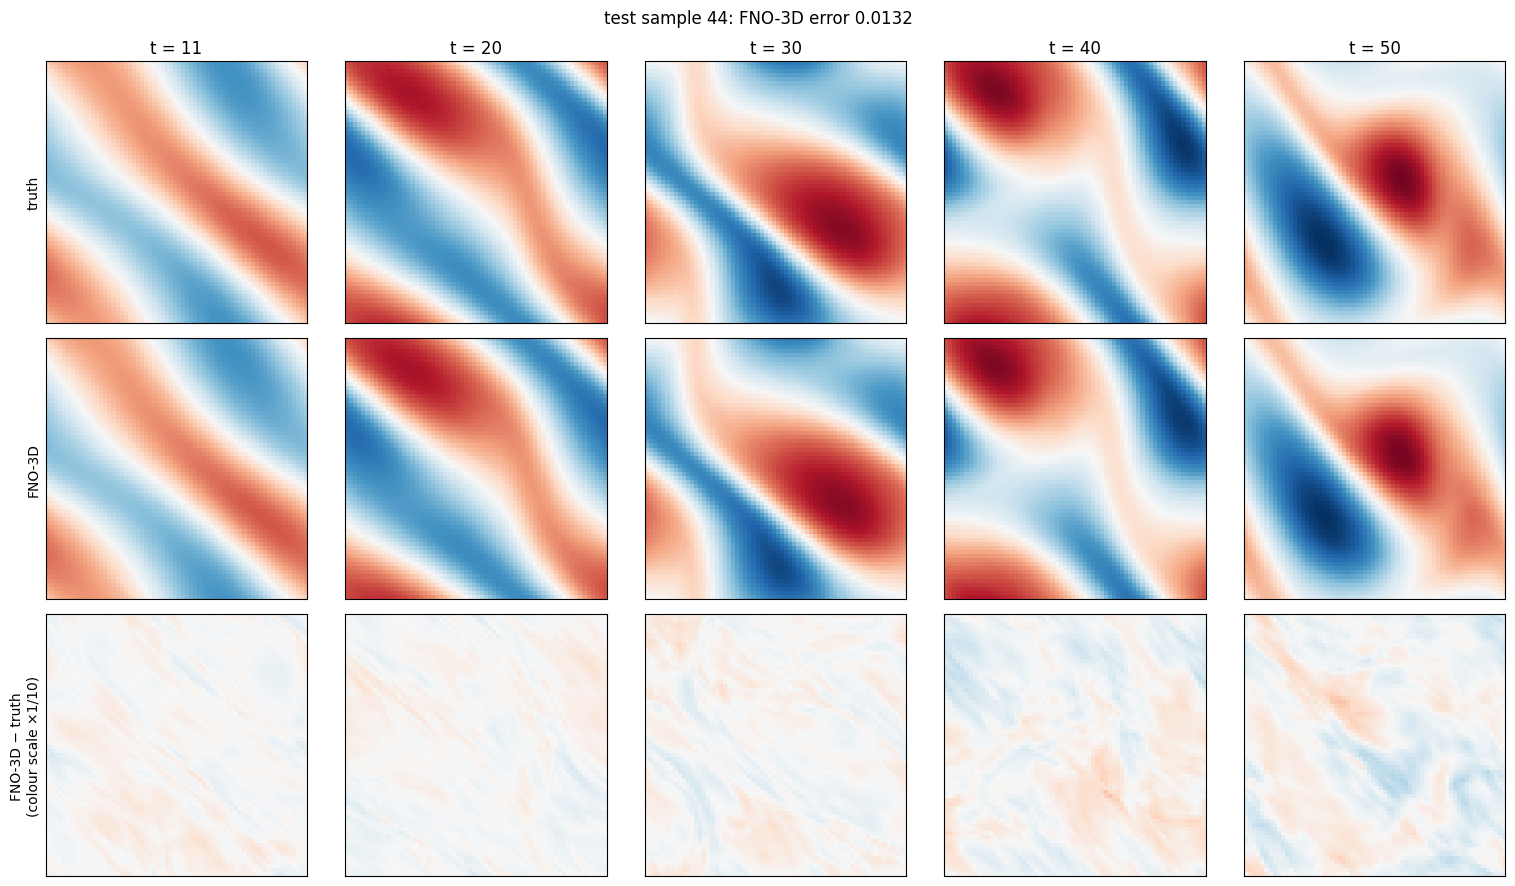

In [12]:
P3 = predict(model3, Xte, BATCH3)
P2 = predict(model2, Xte, BATCH2) if model2 is not None else None
e3 = rel_l2(P3, Yte)
i = torch.argsort(e3)[len(e3) // 2].item()
show_t = sorted(set([T_IN + 1, T_IN + T_OUT // 4, T_IN + T_OUT // 2, T_IN + 3 * T_OUT // 4, T_FINAL]))
rows = [("truth", Yte[i]), ("FNO-3D", P3[i]), ("FNO-3D − truth", P3[i] - Yte[i])]
if P2 is not None: rows += [("FNO-2D", P2[i]), ("FNO-2D − truth", P2[i] - Yte[i])]
vm = Yte[i].abs().max().item()
fig, axs = plt.subplots(len(rows), len(show_t), figsize=(3.1 * len(show_t), 3.0 * len(rows)))
for r, (lab, data) in enumerate(rows):
    for c, t in enumerate(show_t):
        img = data[:, :, t - T_IN - 1]
        lim = vm if "−" not in lab else vm / 10
        axs[r, c].imshow(img.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-lim, vmax=lim)
        axs[r, c].set_xticks([]); axs[r, c].set_yticks([])
        if r == 0: axs[r, c].set_title(f"t = {t}")
        if c == 0: axs[r, c].set_ylabel(lab + ("\n(colour scale ×1/10)" if "−" in lab else ""))
fig.suptitle(f"test sample {i}: FNO-3D error {e3[i]:.4f}" + (f", FNO-2D error {rel_l2(P2, Yte)[i]:.4f}" if P2 is not None else ""))
plt.tight_layout(); plt.show()

### 8c. Error as a function of time
Mean (over the test set) relative error of each predicted frame. FNO-2D feeds its own predictions back, so its
errors can accumulate along the rollout; FNO-3D predicts all frames at once.

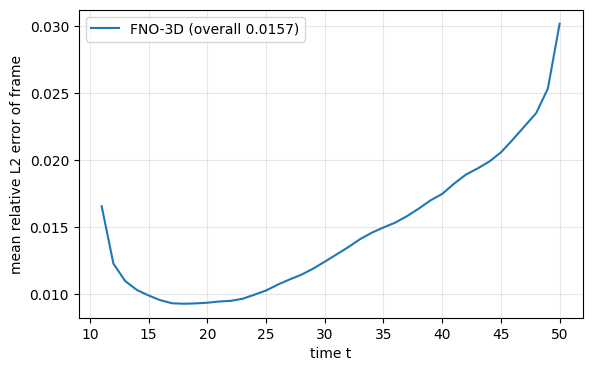

In [13]:
per_t = lambda P: ((P - Yte).flatten(1, 2).norm(dim=1) / Yte.flatten(1, 2).norm(dim=1)).mean(0)
tt = np.arange(T_IN + 1, T_FINAL + 1)
plt.figure(figsize=(6.5, 4))
plt.plot(tt, per_t(P3), label=f"FNO-3D (overall {e3.mean():.4f})")
if P2 is not None: plt.plot(tt, per_t(P2), label=f"FNO-2D (overall {rel_l2(P2, Yte).mean():.4f})")
plt.xlabel("time t"); plt.ylabel("mean relative L2 error of frame"); plt.grid(alpha=.3); plt.legend(); plt.show()

### 8d. Energy spectra at the final time
The spectral weights only act on $|k_j| < 8$. Content above that comes from $W$, the activations and $Q$.

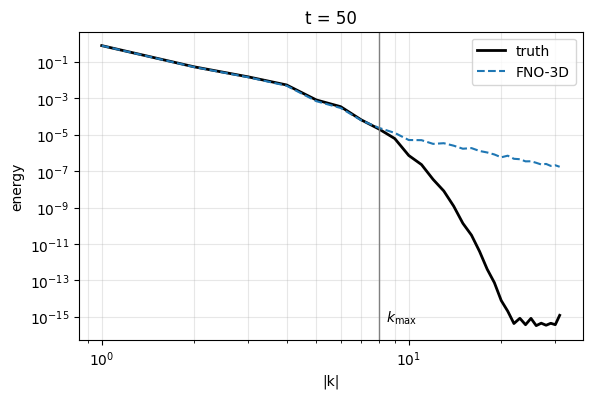

In [14]:
ks = np.arange(1, S // 2)
plt.figure(figsize=(6.5, 4))
plt.loglog(ks, radial_spectrum(Yte[..., -1])[1:], "k", lw=2, label="truth")
plt.loglog(ks, radial_spectrum(P3[..., -1])[1:], "--", label="FNO-3D")
if P2 is not None: plt.loglog(ks, radial_spectrum(P2[..., -1])[1:], ":", label="FNO-2D")
plt.axvline(MODES3, color="gray", lw=1); plt.text(MODES3 * 1.05, plt.ylim()[0] * 10, r"$k_{\max}$")
plt.xlabel("|k|"); plt.ylabel("energy"); plt.title(f"t = {T_FINAL}"); plt.grid(alpha=.3, which="both"); plt.legend(); plt.show()

### 8e. Zero-shot super-resolution
The FNO-3D trained on $64\times64$ is evaluated on the test set at the solver resolution (`N_SOLVE`), never seen
in training. (The paper's Figure 1 does this for $\nu=10^{-4}$, from $64\times64\times20$ to $256\times256\times80$.)

FNO-3D error at 64^2 (training resolution): 0.0157
FNO-3D error at 128^2 (zero-shot):        0.0157


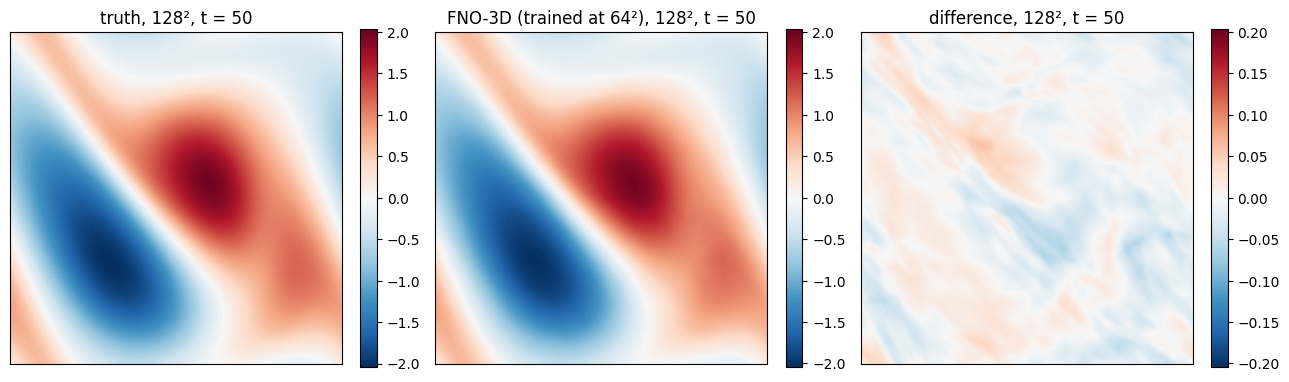

In [15]:
Xf, Yf = to_io(w_test_full)
Pf = predict(model3, Xf, max(1, BATCH3 // 4))
ef = rel_l2(Pf, Yf)
print(f"FNO-3D error at {S}^2 (training resolution): {e3.mean():.4f}")
print(f"FNO-3D error at {N_SOLVE}^2 (zero-shot):        {ef.mean():.4f}")
fig, axs = plt.subplots(1, 3, figsize=(13, 4))
for ax, img, t_ in zip(axs, [Yf[i, :, :, -1], Pf[i, :, :, -1], Pf[i, :, :, -1] - Yf[i, :, :, -1]],
                       ["truth", "FNO-3D (trained at %d²)" % S, "difference"]):
    lim = vm if t_ != "difference" else vm / 10
    im = ax.imshow(img.T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"{t_}, {N_SOLVE}², t = {T_FINAL}"); ax.set_xticks([]); ax.set_yticks([]); fig.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

### 8f. Inference time
Wall-clock time to predict the 40 output frames for one batch, per sample. Compare with the solver.

In [16]:
def timeit(fn, reps=3):
    fn(); torch.cuda.synchronize() if device.type == "cuda" else None
    t0 = time.time()
    for _ in range(reps): fn()
    torch.cuda.synchronize() if device.type == "cuda" else None
    return (time.time() - t0) / reps

xb = enc(Xte[:BATCH3]).to(device)
with torch.no_grad():
    t3 = timeit(lambda: model3.eval()(xb)) / len(xb)
    msg = f"FNO-3D: {1e3 * t3:.2f} ms per sample"
    if model2 is not None:
        t2 = timeit(lambda: model2.eval()(xb)) / len(xb); msg += f" | FNO-2D: {1e3 * t2:.2f} ms per sample"
w0b = sample_w0(BATCH3, N_SOLVE)
ts = timeit(lambda: ns_solve(w0b, T=T_FINAL), reps=1) / BATCH3
print(msg + f" | solver ({N_SOLVE}², batched): {1e3 * ts:.0f} ms per sample")

FNO-3D: 13.95 ms per sample | solver (128², batched): 535 ms per sample
